# Paper 3: Hur, Kim & Park (2022) — QCNN on CIFAR-10
### *"Quantum convolutional neural network for classical data classification"* (Quantum Machine Intelligence 4, 3 (2022) / arXiv:2108.00661)

---

## 1. Experimental Overview (CIFAR-10: Airplane vs. Automobile)
This notebook extends the 8-qubit variational Quantum Convolutional Neural Network (QCNN) architecture to **CIFAR-10** (Class 0: Airplane vs. Class 1: Automobile).

### Key Technical Attributes & Rationale:
1. **Qubit Allocation & Register Width ($N = 8$):**
   - **High-Dimensional Input Space:** Raw CIFAR-10 images are $32 \times 32 \times 3 = 3,072$ dimensions (color RGB pixels).
   - **Classical Dimensionality Reduction:** Classical Principal Component Analysis (PCA) compresses the 3,072-dimensional space down to the **top 8 principal components**, capturing the primary structural variances between vehicle classes.
   - **Hierarchical Binary Tree Pooling:** QCNN halves the active register width at each pooling layer ($8 \to 4 \to 2 \to 1$). Across $L = 3$ layers, reaching exactly **1 surviving measurement qubit** requires an initial register width of $2^L = 2^3 = 8$ qubits.
2. **Quantum Data Encodings:**
   - **Qubit (Angle) Encoding:** Depth $\mathcal{O}(1)$ parallel $R_y(x_i)$ rotations on 8 wires, preserving continuous component values.
   - **Amplitude Encoding:** $L_2$-normalized statevector initialization across computational basis states.
3. **Ansatz Ablation:** Circuit 6 ($SO(4)$ real orthogonal, 24 parameters) vs. Circuit 9 (universal $SU(4)$, 51 parameters).
4. **Measurement Strategies:** Probability measurement $P(|0\rangle), P(|1\rangle)$ (Cross-Entropy Loss) vs. Pauli-Z expectation $\langle Z \rangle$ (MSE Loss).
5. **Optimization Dynamics:** Comparative benchmark across **Adam**, **SGD with Momentum (0.9)**, and **RMSprop**.

### Step 0: Environment Setup & Package Dependencies

In [ ]:
!pip install pennylane torch torchvision scikit-learn matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 30.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 18.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 63.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 49.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 54.4 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


### Step 1: Simulator Device & Precision Setup
Enforce `torch.float64` double precision to match PennyLane's `default.qubit` simulator precision.

In [ ]:
import os
import time
import pickle
import numpy as np
import matplotlib.pyplot as plt

import pennylane as qml
import torch
import torch.nn as nn
from torchvision import datasets
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

# Enforce Double Precision throughout
torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"Device: {device} | Precision: float64 enforced")

Device: cuda | Precision: float64 enforced


### Step 2: CIFAR-10 Data Pipeline & PCA-8 Preprocessing
We extract Class 0 (Airplane) and Class 1 (Automobile), normalize the 3,072 pixel values to $[0, 1]$, and apply PCA to reduce to 8 components:
- **Angle Features:** Scaled to $[0, \pi]$ for Bloch sphere rotations.
- **Amplitude Features:** $L_2$-normalized to unit magnitude.

In [ ]:
cache_dir = "./cache_cifar"
os.makedirs(cache_dir, exist_ok=True)
cache_file = os.path.join(cache_dir, "cifar10_pca8_binary_0_1.npz")

if os.path.exists(cache_file):
    data = np.load(cache_file)
    X_tr_angle = data["X_tr_angle"]
    X_tr_amp = data["X_tr_amp"]
    y_train = data["y_train"]
    X_te_angle = data["X_te_angle"]
    X_te_amp = data["X_te_amp"]
    y_test = data["y_test"]
    print("Loaded preprocessed CIFAR-10 PCA-8 binary dataset from cache.")
else:
    print("Downloading CIFAR-10 and extracting Class 0 (Airplane) vs Class 1 (Automobile)...")
    train_ds = datasets.CIFAR10(root='./data_cifar', train=True, download=True)
    test_ds = datasets.CIFAR10(root='./data_cifar', train=False, download=True)

    tr_targets = np.array(train_ds.targets)
    te_targets = np.array(test_ds.targets)

    tr_mask = (tr_targets == 0) | (tr_targets == 1)
    te_mask = (te_targets == 0) | (te_targets == 1)

    # Flatten 32x32x3 = 3072 features normalized to [0, 1]
    X_tr_raw = train_ds.data[tr_mask].reshape(-1, 3072).astype(np.float64) / 255.0
    y_tr_raw = tr_targets[tr_mask]
    X_te_raw = test_ds.data[te_mask].reshape(-1, 3072).astype(np.float64) / 255.0
    y_te_raw = te_targets[te_mask]

    y_train = (y_tr_raw == 1).astype(np.int64)
    y_test = (y_te_raw == 1).astype(np.int64)

    print("Fitting PCA-8 on 3072-dimensional raw color vectors...")
    pca = PCA(n_components=8, random_state=42)
    X_tr_pca = pca.fit_transform(X_tr_raw)
    X_te_pca = pca.transform(X_te_raw)

    scaler = MinMaxScaler(feature_range=(0, np.pi))
    X_tr_angle = scaler.fit_transform(X_tr_pca)
    X_te_angle = scaler.transform(X_te_pca)

    def l2_norm(X):
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        return X / norms

    X_tr_amp = l2_norm(X_tr_pca)
    X_te_amp = l2_norm(X_te_pca)

    np.savez(cache_file, X_tr_angle=X_tr_angle, X_tr_amp=X_tr_amp, y_train=y_train,
             X_te_angle=X_te_angle, X_te_amp=X_te_amp, y_test=y_test)
    print("Preprocessed and cached CIFAR-10 PCA-8 binary dataset.")

print(f"Training samples: {len(y_train)} | Test samples: {len(y_test)}")
print(f"Angle range: [{X_tr_angle.min():.2f}, {X_tr_angle.max():.2f}] rad | Sample L2 norm: {np.linalg.norm(X_tr_amp[0]):.4f}")

100%|██████████| 170M/170M [00:14<00:00, 11.7MB/s]


Fitting PCA-8 on 3072-dimensional raw color vectors...
Preprocessed and cached CIFAR-10 PCA-8 binary dataset.
Training samples: 10000 | Test samples: 2000
Angle range: [0.00, 3.14] rad | Sample L2 norm: 1.0000


### Step 3: Gate-Level Quantum Encodings & Ansatze

In [ ]:
def qubit_encoding(x, wires):
    for i, w in enumerate(wires):
        qml.RY(x[i], wires=w)

def amplitude_encoding(x, wires):
    dim = 2 ** len(wires)
    padded = np.zeros(dim, dtype=np.float64)
    norm = np.linalg.norm(x)
    padded[:len(x)] = x / (norm if norm != 0 else 1.0)
    qml.StatePrep(padded, wires=wires)

def conv_ansatz_6(params, wires):
    qml.RY(params[0], wires=wires[0])
    qml.RY(params[1], wires=wires[1])
    qml.CNOT(wires=[wires[0], wires[1]])
    qml.RY(params[2], wires=wires[0])
    qml.RY(params[3], wires=wires[1])
    qml.CNOT(wires=[wires[1], wires[0]])
    qml.RY(params[4], wires=wires[0])
    qml.RY(params[5], wires=wires[1])

def conv_ansatz_9(params, wires):
    qml.RZ(params[0], wires=wires[0])
    qml.RY(params[1], wires=wires[0])
    qml.RZ(params[2], wires=wires[0])
    qml.RZ(params[3], wires=wires[1])
    qml.RY(params[4], wires=wires[1])
    qml.RZ(params[5], wires=wires[1])
    qml.CNOT(wires=[wires[1], wires[0]])
    qml.RZ(params[6], wires=wires[0])
    qml.RY(params[7], wires=wires[1])
    qml.CNOT(wires=[wires[0], wires[1]])
    qml.RY(params[8], wires=wires[1])
    qml.CNOT(wires=[wires[1], wires[0]])
    qml.RZ(params[9], wires=wires[0])
    qml.RY(params[10], wires=wires[0])
    qml.RZ(params[11], wires=wires[0])
    qml.RZ(params[12], wires=wires[1])
    qml.RY(params[13], wires=wires[1])
    qml.RZ(params[14], wires=wires[1])

def pool_ansatz(params, wires):
    qml.CRZ(params[0], wires=[wires[0], wires[1]])
    qml.PauliX(wires=wires[0])
    qml.CRX(params[1], wires=[wires[0], wires[1]])
    qml.PauliX(wires=wires[0])

def qcnn_conv_layer(ansatz_fn, params, wires):
    n = len(wires)
    for i in range(0, n - 1, 2):
        ansatz_fn(params, wires=[wires[i], wires[i + 1]])
    for i in range(1, n - 1, 2):
        ansatz_fn(params, wires=[wires[i], wires[i + 1]])
    if n > 2:
        ansatz_fn(params, wires=[wires[-1], wires[0]])

def qcnn_pool_layer(params, source_wires, sink_wires):
    for s, t in zip(source_wires, sink_wires):
        pool_ansatz(params, wires=[s, t])

### Step 4: 8-Qubit QNode and PyTorch Hybrid Classifier

In [ ]:
dev8 = qml.device("default.qubit", wires=8)

def build_qcnn_qnode(ansatz_name="circuit_6", encoding_name="qubit", output_mode="probs"):
    ansatz_fn = conv_ansatz_6 if ansatz_name == "circuit_6" else conv_ansatz_9
    p_conv = 6 if ansatz_name == "circuit_6" else 15
    encode_fn = qubit_encoding if encoding_name == "qubit" else amplitude_encoding

    @qml.qnode(dev8, interface="torch", diff_method="backprop")
    def circuit(x, params):
        encode_fn(x, wires=range(8))
        c1 = params[0 : p_conv]
        p1 = params[p_conv : p_conv + 2]
        c2 = params[p_conv + 2 : 2 * p_conv + 2]
        p2 = params[2 * p_conv + 2 : 2 * p_conv + 4]
        c3 = params[2 * p_conv + 4 : 3 * p_conv + 4]
        p3 = params[3 * p_conv + 4 : 3 * p_conv + 6]

        # Layer 1: 8 -> 4
        qcnn_conv_layer(ansatz_fn, c1, wires=[0, 1, 2, 3, 4, 5, 6, 7])
        qcnn_pool_layer(p1, source_wires=[0, 2, 4, 6], sink_wires=[1, 3, 5, 7])
        # Layer 2: 4 -> 2
        qcnn_conv_layer(ansatz_fn, c2, wires=[1, 3, 5, 7])
        qcnn_pool_layer(p2, source_wires=[1, 5], sink_wires=[3, 7])
        # Layer 3: 2 -> 1
        ansatz_fn(c3, wires=[3, 7])
        pool_ansatz(p3, wires=[3, 7])

        if output_mode == "probs":
            return qml.probs(wires=7)
        else:
            return qml.expval(qml.PauliZ(7))
    return circuit

class ClassicalQCNNClassifier(nn.Module):
    def __init__(self, ansatz_name="circuit_6", encoding_name="qubit", output_mode="probs", seed=42):
        super().__init__()
        self.ansatz_name = ansatz_name
        self.encoding_name = encoding_name
        self.output_mode = output_mode

        p_conv = 6 if ansatz_name == "circuit_6" else 15
        num_params = 3 * p_conv + 6
        torch.manual_seed(seed)
        self.params = nn.Parameter(0.1 * torch.randn(num_params, dtype=torch.float64))
        self.qnode = build_qcnn_qnode(ansatz_name, encoding_name, output_mode)

    def forward(self, x_batch):
        if x_batch.ndim == 1:
            return self.qnode(x_batch, self.params)
        return torch.stack([self.qnode(x, self.params) for x in x_batch])

class TinyCNN(nn.Module):
    def __init__(self, out_channels=2):
        super().__init__()
        self.conv1 = nn.Conv1d(1, out_channels, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(2)
        self.fc = nn.Linear(out_channels * 4, 2)

    def forward(self, x):
        if x.ndim == 1:
            x = x.unsqueeze(0)
        x = x.unsqueeze(1)
        x = self.pool(torch.relu(self.conv1(x)))
        x = x.view(x.size(0), -1)
        return self.fc(x)

### Step 5: Training Pipeline Function

In [ ]:
def train_model(model, X_train, y_train, X_test, y_test, loss_type="ce",
                batch_size=25, n_iterations=200, lr=0.01, opt_name="Adam"):
    is_classical = isinstance(model, TinyCNN)
    if opt_name == "Adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    elif opt_name == "SGD_Momentum":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif opt_name == "RMSprop":
        optimizer = torch.optim.RMSprop(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    loss_history = []
    n_train = len(X_train)

    for it in range(n_iterations):
        idx = np.random.choice(n_train, batch_size, replace=False)
        batch_x = torch.tensor(X_train[idx], dtype=torch.float64)
        batch_y = torch.tensor(y_train[idx], dtype=torch.long)

        optimizer.zero_grad()
        if is_classical:
            logits = model(batch_x)
            if loss_type == "ce":
                loss = nn.CrossEntropyLoss()(logits, batch_y)
            else:
                y_targ = (1.0 - 2.0 * batch_y.to(torch.float64)).unsqueeze(1)
                pred_val = logits[:, 0:1] - logits[:, 1:2]
                loss = nn.MSELoss()(pred_val, y_targ)
        else:
            if loss_type == "ce":
                probs = model(batch_x)
                eps = 1e-9
                loss = -torch.mean(batch_y * torch.log(probs[:, 1] + eps) +
                                   (1.0 - batch_y) * torch.log(probs[:, 0] + eps))
            else:
                exp_vals = model(batch_x)
                y_targ = 1.0 - 2.0 * batch_y.to(torch.float64)
                loss = torch.mean((exp_vals - y_targ) ** 2)

        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())

    test_len = min(500, len(X_test))
    te_x = torch.tensor(X_test[:test_len], dtype=torch.float64)
    te_y = y_test[:test_len]

    model.eval()
    with torch.no_grad():
        if is_classical:
            preds = torch.argmax(model(te_x), dim=1).numpy()
        else:
            if loss_type == "ce":
                probs = model(te_x)
                preds = (probs[:, 1] > probs[:, 0]).long().numpy()
            else:
                preds = (model(te_x) < 0.0).long().numpy()

    return {"final_acc": np.mean(preds == te_y), "loss_history": np.array(loss_history)}

### Step 6: Measurement Technique Benchmark (Cross-Entropy vs MSE Loss)

In [ ]:
seeds = [42, 43, 44, 45, 46]
ce_accs, mse_accs = [], []
ce_losses, mse_losses = [], []

print("Evaluating Measurement Formulations on CIFAR-10 (Circuit 6, Qubit Encoding, 5 Seeds)...")
for s in seeds:
    m_ce = ClassicalQCNNClassifier("circuit_6", "qubit", "probs", seed=s)
    res_ce = train_model(m_ce, X_tr_angle, y_train, X_te_angle, y_test, loss_type="ce")
    ce_accs.append(res_ce["final_acc"])
    ce_losses.append(res_ce["loss_history"])

    m_mse = ClassicalQCNNClassifier("circuit_6", "qubit", "expval", seed=s)
    res_mse = train_model(m_mse, X_tr_angle, y_train, X_te_angle, y_test, loss_type="mse")
    mse_accs.append(res_mse["final_acc"])
    mse_losses.append(res_mse["loss_history"])
    print(f"  Seed {s} -> CE: {res_ce['final_acc']*100:.2f}% | MSE: {res_mse['final_acc']*100:.2f}%")

print(f"\nCross-Entropy (Probabilities) : {np.mean(ce_accs)*100:.2f}% ± {np.std(ce_accs)*100:.2f}%")
print(f"Mean Squared Error (Pauli-Z)   : {np.mean(mse_accs)*100:.2f}% ± {np.std(mse_accs)*100:.2f}%")

Evaluating Measurement Formulations on CIFAR-10 (Circuit 6, Qubit Encoding, 5 Seeds)...
  Seed 42 -> CE: 71.20% | MSE: 69.80%
  Seed 43 -> CE: 59.40% | MSE: 69.60%
  Seed 44 -> CE: 69.20% | MSE: 67.20%
  Seed 45 -> CE: 65.20% | MSE: 72.20%
  Seed 46 -> CE: 67.60% | MSE: 65.40%

Cross-Entropy (Probabilities) : 66.52% ± 4.07%
Mean Squared Error (Pauli-Z)   : 68.84% ± 2.34%


### Step 7: Optimizer Benchmark (Adam vs. SGD-Momentum vs. RMSprop)

In [ ]:
optimizers_list = ["Adam", "SGD_Momentum", "RMSprop"]
opt_benchmark_results = {}
opt_seeds = [42, 43, 44]

print("Running Optimizer Benchmark on CIFAR-10 (Circuit 6, Qubit Encoding, 150 iterations)...")
for opt in optimizers_list:
    opt_accs = []
    for s in opt_seeds:
        m = ClassicalQCNNClassifier("circuit_6", "qubit", "probs", seed=s)
        res = train_model(m, X_tr_angle, y_train, X_te_angle, y_test, loss_type="ce",
                          n_iterations=150, lr=0.01, opt_name=opt)
        opt_accs.append(res["final_acc"])
    mean_acc = np.mean(opt_accs) * 100
    std_acc = np.std(opt_accs) * 100
    opt_benchmark_results[opt] = (mean_acc, std_acc)
    print(f"  Optimizer: {opt:<14} | Acc: {mean_acc:.2f}% ± {std_acc:.2f}%")

Running Optimizer Benchmark on CIFAR-10 (Circuit 6, Qubit Encoding, 150 iterations)...
  Optimizer: Adam           | Acc: 71.53% ± 0.81%
  Optimizer: SGD_Momentum   | Acc: 64.40% ± 1.88%
  Optimizer: RMSprop        | Acc: 66.00% ± 3.15%


### Step 8: Full Benchmark Grid — Circuit 6 vs Circuit 9

In [ ]:
NUM_SEEDS = 3
GRID_ITERS = 200
ENCODINGS = ["qubit", "amplitude"]
ansatze = ["circuit_6", "circuit_9"]
SEEDS = seeds[:NUM_SEEDS]

CACHE = "bench_cache_cifar.pkl"
cache = pickle.load(open(CACHE, "rb")) if os.path.exists(CACHE) else {}

def run_cfg(key, make_model, X_tr, X_te, seed):
    key = key + (GRID_ITERS,)
    if key in cache:
        return cache[key]
    np.random.seed(seed); torch.manual_seed(seed)
    res = train_model(make_model(), X_tr, y_train, X_te, y_test,
                      loss_type="ce", n_iterations=GRID_ITERS, opt_name="Adam")
    cache[key] = {"final_acc": res["final_acc"], "loss_history": res["loss_history"]}
    pickle.dump(cache, open(CACHE, "wb"))
    return cache[key]

all_enc = ["qubit", "amplitude", "dense"]
table_cifar_results = {a: {e: [] for e in all_enc} for a in ansatze}
all_loss_curves = {a: {e: [] for e in all_enc} for a in ansatze}

skip = set()
if GRID_ITERS == len(ce_losses[0]):
    table_cifar_results["circuit_6"]["qubit"] = list(ce_accs[:NUM_SEEDS])
    all_loss_curves["circuit_6"]["qubit"] = list(ce_losses[:NUM_SEEDS])
    skip = {("circuit_6", "qubit")}

for a in ansatze:
    for e in ENCODINGS:
        if (a, e) in skip:
            continue
        X_tr = X_tr_amp if e == "amplitude" else X_tr_angle
        X_te = X_te_amp if e == "amplitude" else X_te_angle
        for s in SEEDS:
            t0 = time.time()
            r = run_cfg((a, e, s),
                        lambda: ClassicalQCNNClassifier(a, e, "probs", seed=s),
                        X_tr, X_te, s)
            table_cifar_results[a][e].append(r["final_acc"])
            all_loss_curves[a][e].append(r["loss_history"])
            print(f"{a} | {e} | seed {s} | acc {r['final_acc']*100:.2f}% | elapsed {time.time()-t0:.0f}s", flush=True)

tiny26_accs, tiny26_losses, tiny50_accs, tiny50_losses = [], [], [], []
for s in SEEDS:
    for oc, accs, losses in [(2, tiny26_accs, tiny26_losses), (4, tiny50_accs, tiny50_losses)]:
        np.random.seed(s); torch.manual_seed(s)
        r = train_model(TinyCNN(out_channels=oc), X_tr_angle, y_train, X_te_angle, y_test,
                        loss_type="ce", n_iterations=GRID_ITERS, opt_name="Adam")
        accs.append(r["final_acc"]); losses.append(r["loss_history"])
print("CIFAR-10 benchmark grid completed.")

/tmp/ipykernel_465/1338548872.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  padded[:len(x)] = x / (norm if norm != 0 else 1.0)


circuit_6 | amplitude | seed 42 | acc 60.60% | elapsed 420s
circuit_6 | amplitude | seed 43 | acc 58.60% | elapsed 422s
circuit_6 | amplitude | seed 44 | acc 58.20% | elapsed 406s
circuit_9 | qubit | seed 42 | acc 70.60% | elapsed 826s
circuit_9 | qubit | seed 43 | acc 68.00% | elapsed 827s
circuit_9 | qubit | seed 44 | acc 68.00% | elapsed 826s
circuit_9 | amplitude | seed 42 | acc 63.00% | elapsed 813s
circuit_9 | amplitude | seed 43 | acc 61.40% | elapsed 817s
circuit_9 | amplitude | seed 44 | acc 62.00% | elapsed 798s
CIFAR-10 benchmark grid completed.


### Step 9: Formatted CIFAR-10 Summary Table & Visualizations

TABLE: CIFAR-10 (AIRPLANE vs AUTOMOBILE) BENCHMARK (3 SEEDS)
Architecture / Ansatz        | Params   | Qubit (Angle)    | Amplitude        | Dense Qubit     
-----------------------------------------------------------------------------------------------
QCNN Circuit 6 (SO(4))       | 24       | 66.60 ± 5.16%    | 59.13 ± 1.05%    | N/A (Omitted)   
QCNN Circuit 9 (SU(4))       | 51       | 68.87 ± 1.23%    | 62.13 ± 0.66%    | N/A (Omitted)   
-----------------------------------------------------------------------------------------------
Classical TinyCNN-26         | 26       | 65.47 ± 11.40%   | N/A (Classical)  | N/A (Classical) 
Classical TinyCNN-50         | 50       | 70.67 ± 1.25%    | N/A (Classical)  | N/A (Classical) 


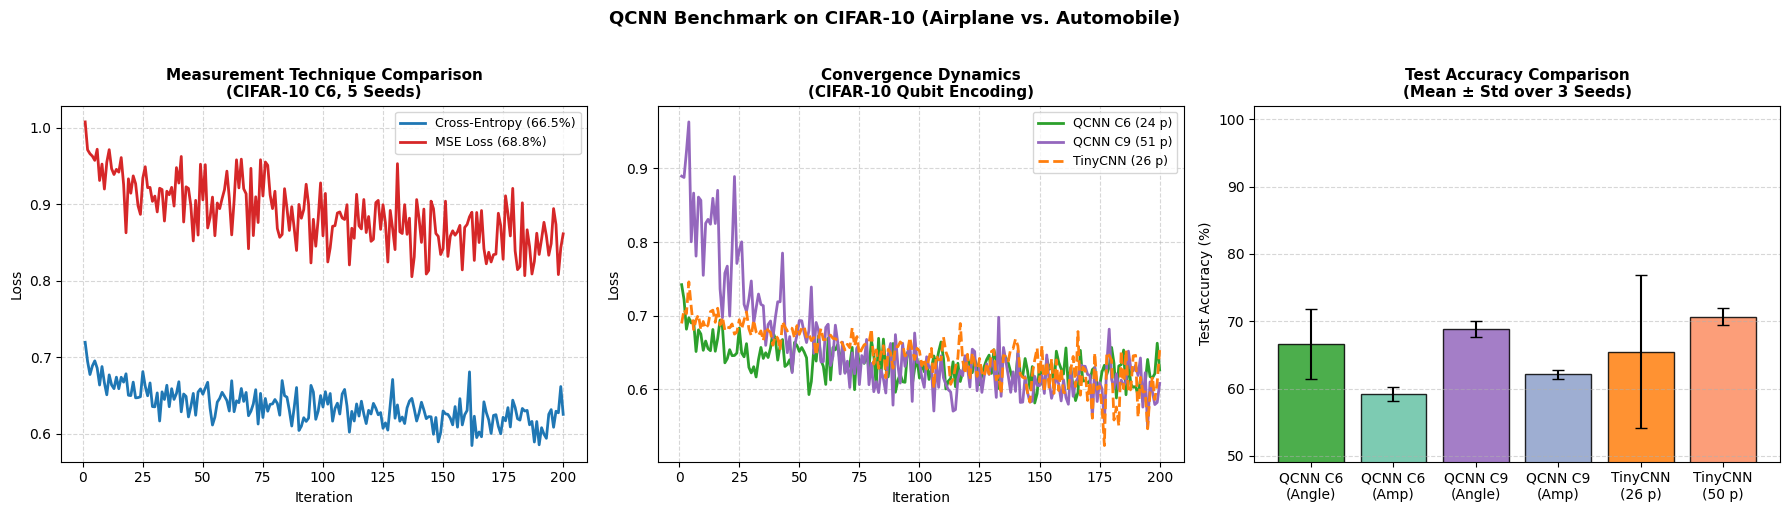

In [ ]:
print("=" * 95)
print(f"TABLE: CIFAR-10 (AIRPLANE vs AUTOMOBILE) BENCHMARK ({NUM_SEEDS} SEEDS)")
print(f"{'Architecture / Ansatz':<28} | {'Params':<8} | {'Qubit (Angle)':<16} | {'Amplitude':<16} | {'Dense Qubit':<16}")
print("-" * 95)

for a, name, pcount in [("circuit_6", "QCNN Circuit 6 (SO(4))", 24), ("circuit_9", "QCNN Circuit 9 (SU(4))", 51)]:
    q_str = f"{np.mean(table_cifar_results[a]['qubit'])*100:.2f} ± {np.std(table_cifar_results[a]['qubit'])*100:.2f}%"
    a_str = f"{np.mean(table_cifar_results[a]['amplitude'])*100:.2f} ± {np.std(table_cifar_results[a]['amplitude'])*100:.2f}%"
    d_str = "N/A (Omitted)"
    print(f"{name:<28} | {pcount:<8} | {q_str:<16} | {a_str:<16} | {d_str:<16}")

t26_str = f"{np.mean(tiny26_accs)*100:.2f} ± {np.std(tiny26_accs)*100:.2f}%"
t50_str = f"{np.mean(tiny50_accs)*100:.2f} ± {np.std(tiny50_accs)*100:.2f}%"
print("-" * 95)
print(f"{'Classical TinyCNN-26':<28} | {26:<8} | {t26_str:<16} | {'N/A (Classical)':<16} | {'N/A (Classical)':<16}")
print(f"{'Classical TinyCNN-50':<28} | {50:<8} | {t50_str:<16} | {'N/A (Classical)':<16} | {'N/A (Classical)':<16}")
print("=" * 95)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
iters = np.arange(1, 201)

# Panel 1: Loss comparison
axes[0].plot(iters, np.mean(ce_losses, axis=0), label=f"Cross-Entropy ({np.mean(ce_accs)*100:.1f}%)", color="#1f77b4", lw=2)
axes[0].plot(iters, np.mean(mse_losses, axis=0), label=f"MSE Loss ({np.mean(mse_accs)*100:.1f}%)", color="#d62728", lw=2)
axes[0].set_title("Measurement Technique Comparison\n(CIFAR-10 C6, 5 Seeds)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Iteration", fontsize=10); axes[0].set_ylabel("Loss", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5); axes[0].legend(fontsize=9)

# Panel 2: Model convergence
axes[1].plot(iters, np.mean(all_loss_curves["circuit_6"]["qubit"], axis=0), label="QCNN C6 (24 p)", color="#2ca02c", lw=2)
axes[1].plot(iters, np.mean(all_loss_curves["circuit_9"]["qubit"], axis=0), label="QCNN C9 (51 p)", color="#9467bd", lw=2)
axes[1].plot(iters, np.mean(tiny26_losses, axis=0), label="TinyCNN (26 p)", color="#ff7f0e", lw=2, linestyle="--")
axes[1].set_title("Convergence Dynamics\n(CIFAR-10 Qubit Encoding)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Iteration", fontsize=10); axes[1].set_ylabel("Loss", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5); axes[1].legend(fontsize=9)

# Panel 3: Test Accuracies
models_labels = ["QCNN C6\n(Angle)", "QCNN C6\n(Amp)", "QCNN C9\n(Angle)", "QCNN C9\n(Amp)", "TinyCNN\n(26 p)", "TinyCNN\n(50 p)"]
means = [np.mean(table_cifar_results["circuit_6"]["qubit"])*100, np.mean(table_cifar_results["circuit_6"]["amplitude"])*100,
         np.mean(table_cifar_results["circuit_9"]["qubit"])*100, np.mean(table_cifar_results["circuit_9"]["amplitude"])*100,
         np.mean(tiny26_accs)*100, np.mean(tiny50_accs)*100]
stds = [np.std(table_cifar_results["circuit_6"]["qubit"])*100, np.std(table_cifar_results["circuit_6"]["amplitude"])*100,
        np.std(table_cifar_results["circuit_9"]["qubit"])*100, np.std(table_cifar_results["circuit_9"]["amplitude"])*100,
        np.std(tiny26_accs)*100, np.std(tiny50_accs)*100]
axes[2].bar(models_labels, means, yerr=stds, capsize=4, color=["#2ca02c", "#66c2a5", "#9467bd", "#8da0cb", "#ff7f0e", "#fc8d62"], alpha=0.85, edgecolor="black")
axes[2].set_ylim(min(means) - 10, 102)
axes[2].set_title(f"Test Accuracy Comparison\n(Mean ± Std over {NUM_SEEDS} Seeds)", fontsize=11, fontweight="bold")
axes[2].set_ylabel("Test Accuracy (%)", fontsize=10)
axes[2].grid(True, axis="y", linestyle="--", alpha=0.5)

plt.suptitle("QCNN Benchmark on CIFAR-10 (Airplane vs. Automobile)", fontsize=13, y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()